# UAV FP — Optimizador V52.4: competencia entre topologías de avión de ala fija

> **Versión V52.4.** Cambios sobre esta versión: `V52.4.1`, `V52.4.2`… Si se agrega o modifica un módulo, pasa a la versión siguiente. Ver `VERSIONES.md`.

Hermano de **`01_Optimizacion_Ala.ipynb`**. Aquel optimiza **una sola** topología (el ala volante); este hace **competir cinco topologías de avión completo** bajo la **misma misión**, para responder una pregunta que el notebook 01 no puede: *¿es el ala volante la mejor configuración para esta misión, o lo era solamente porque era la única que estábamos evaluando?*

La lógica estable vive en **`optimizacion_avion/`**; este notebook es el panel de control.

## La misión tiene TRES puntos de vuelo

> **crucero de diseño a 80 km/h** con 3 kg de carga útil, **velocidad máxima de 120 km/h** (restricción dura y término de puntaje), y **poder volar a 10 m/s** (36 km/h) para reconocimiento, despegue y aterrizaje.

El crucero bajó de 120 a 80 km/h el 18/09/2026 (Research Note 15): el alcance eléctrico se maximiza a resistencia mínima, que para este avión cae cerca de 70–80 km/h. Entre la máxima y el vuelo lento hay una relación de velocidades de **3.33 : 1**, o sea un **factor 11 en coeficiente de sustentación**, y por eso los puntos entran juntos a la función objetivo: piden alas **opuestas**. Si se optimizara solo la velocidad, el optimizador convergería a un ala de cuerda mínima que no puede volar lento — un óptimo perfectamente válido del problema equivocado.

Para calibrar cuán exigente es: el **RQ-7B Shadow** tiene máxima/crucero = 1.54:1 y el **Bayraktar TB2**, 1.71:1 — y despegan de pista o catapulta, no en vuelo lento sostenido.

Con los interruptores de la sección 0 se suman el **viento de los sitios** (aire de 1.056 kg/m³, ráfaga de 4.63 m/s, turbulencia) y la **batería dimensionada por alcance** (350 km).

## Las cinco topologías

| topología | descripción | referencia real |
|---|---|---|
| `convencional` | fuselaje + cola cruciforme | baseline estándar de diseño |
| `t_tail` | fuselaje + cola en T | planeadores; horizontal fuera del downwash |
| `v_tail` | fuselaje + cola en V | familia MQ-1 Predator |
| `doble_boom` | dos vigas + doble deriva | familia RQ-7 Shadow / ScanEagle |
| `pod_boom` | fuselaje continuo: diámetro casi constante, afinado solo cerca de la cola (sin góndola ni viga fina) | fuselaje tubular de largo alcance |

**Un resultado teórico que conviene tener a la vista al leer los resultados:** McGeer & Kroo ([J. Aircraft 20(11), 1983](https://ntrs.nasa.gov/citations/19840028263)) muestran que a envergadura dada, y con las restricciones de trimado y estabilidad puestas, la configuración convencional con cola trasera está **muy cerca del óptimo**, y ni el canard ni el tándem la superan salvo casos marginales. O sea: no hay que esperar que una topología exótica gane por goleada. Lo que separa a los candidatos es resistencia parásita, peso estructural y CL_max. Por eso **no** se incluyeron canard ni box-wing: el canard limita el CL_max del ala principal justo cuando es el recurso más escaso, y el box-wing necesita una separación vertical que a 7 kg de construcción artesanal no paga.

## Qué cambió respecto de la versión anterior de este notebook

1. **Parametrización mucho más fina:** ala de 5 estaciones (cuerda, borde de ataque, torsión y diedro estación por estación) **con winglets**, **envergadura variable** (2.0–3.5 m), y fuselaje con morro de forma libre y boat-tail en vez del cono truncado que había. De ~20 a **46–51 parámetros** según la topología.
2. **Incidencia de cola.** Antes iba con `twist = 0` fijo, y eso no era una simplificación sino un error: sin incidencia el avión no tiene con qué trimarse, y el desvío de trim llegaba al 113%. Ahora los candidatos salen con **Cm de crucero = 0.0000**.
3. **Flaps**, modelados deflectando la geometría del perfil y evaluándola con NeuralFoil al Reynolds real del vuelo lento — no con un ΔCL de tabla (ver sección 9).
4. **CL_max a su propio Reynolds.** Antes se estimaba al Re de crucero y se usaba para todo; el CL_max cae ~6% (hasta 11%) al pasar de Re 6.7e5 a 2e5, justo donde el diseño está más apretado.
5. **Catálogo de 19 perfiles** (los 12 del ala volante con los mismos índices, más 7 de alta sustentación).

## Cómo correrlo

Sección **0** (interruptores), **1 y 2** para configurar y sembrar; después **3** (una generación por vez) o **4** (automático). Las secciones **5 a 11** analizan el resultado. Costo: varios segundos por candidato con batería (cada candidato se analiza 2–3 veces para cerrar el lazo masa de batería ↔ resistencia); la competencia completa lleva **horas**.

In [7]:
# Autorecarga: si se editan los .py del paquete mientras el notebook esta
# abierto, Jupyter NO los recarga solo. Estas dos lineas hacen que cada celda
# use la version actual del disco. (Si aparece un AttributeError del tipo
# "module has no attribute ...", es exactamente eso: reinicia el kernel.)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# optimizacion_avion IMPORTA de optimizacion_ala (perfiles, propiedades de
# material, criterio de parada), asi que los dos paquetes tienen que estar
# al lado de este notebook.
sys.path.insert(0, str(Path.cwd()))

import optimizacion_avion as av
import optimizacion_avion.mision_avion as mis
import optimizacion_avion.geometria_avion as geo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import time

print(f"Optimizador {av.VERSION}")
print("Topologias en competencia:")
for nombre, info in av.TOPOLOGIAS.items():
    n_par = len(av.BOUNDS_POR_TOPOLOGIA[nombre])
    lo, hi = info["sm_band"]
    print(f"  {nombre:<14} {n_par:2d} parametros   banda SM [{100*lo:.0f}%, {100*hi:.0f}%]")
    print(f"  {'':<14} {info['nombre']}")
    print(f"  {'':<14} ref: {info['referencia_real']}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Optimizador V52.4
Topologias en competencia:
  convencional   49 parametros   banda SM [10%, 20%]
                 Ala + fuselaje + cola convencional (cruciforme)
                 ref: Motoveleros y UAV de fuselaje único; baseline estándar de diseño
  t_tail         49 parametros   banda SM [10%, 20%]
                 Ala + fuselaje + cola en T
                 ref: Planeadores y UAV con hélice propulsora; horizontal fuera del downwash
  v_tail         46 parametros   banda SM [10%, 20%]
                 Ala + fuselaje + cola en V
                 ref: Familia MQ-1 Predator (cola en V invertida)
  doble_boom     47 parametros   banda SM [10%, 20%]
                 Ala + doble boom + doble estabilizador
                 ref: Familia RQ-7 Shadow / ScanEagle-Integrator
  pod_boom       49 parametros   banda SM [10%, 20%]
                 Fuselaje continuo (diámetro casi constante, afinado en la cola) +

## 0. Interruptores de la rama `bateria-350km`

Todo lo que se puede querer mover está en esta celda; hay que correrla **antes** de la sección 1.

| Interruptor | Qué hace |
|---|---|
| `VIENTO` | `True`: la misión se evalúa con el aire y la ráfaga reales de los sitios (lo de imarzeniuk, `viento.py`). `False`: aire estándar y ráfaga de 3 m/s. |
| `BATERIA` | `True`: la batería se dimensiona para el `ALCANCE_KM` a velocidad de crucero **todo el vuelo**, y su masa entra al peso del avión (`bateria.py`). `False`: vuelve el modelo viejo, con la batería dentro de `MASA_SISTEMAS = 1.5 kg`. |
| `FAMILIAS` | Qué familias (topologías) se corren: una lista, por ejemplo `["pod_boom"]` o `["v_tail", "pod_boom"]`, o `"todas"`. Opciones: `convencional`, `t_tail`, `v_tail`, `doble_boom`, `pod_boom`. |
| `CORRIDA_RAPIDA` | `True`: 8 generaciones de paciencia y máximo 20 (~15–30 min por familia). `False`: 10 / 60, puede tardar **horas** por familia, porque con batería cada candidato cuesta el doble. |
| `GUARDAR_RESULTADOS` | `True`: al final (sección 11b) guarda tablas, gráficos, vistas 3D, líneas de flujo y desgloses en `<CARPETA_RESULTADOS>/<fecha>_<escenario>_<familias>/`. |
| `CARPETA_RESULTADOS` | Dónde se guardan, **fuera del repositorio**. `None` = `Proyecto final/resultados_optimizador/` (al lado de `genetic_wing`); o cualquier ruta de la computadora. |

Los supuestos de la batería (eficiencia propulsiva, reserva, celda, aviónica) son los de abajo; **ninguno está medido**, en particular `ETA_PROPULSIVA_TOTAL`.

In [8]:
import optimizacion_avion.bateria as bat

# ------------------------------ INTERRUPTORES ------------------------------
VIENTO = True            # lo de imarzeniuk (viento de los sitios)
BATERIA = True           # bateria dimensionada por alcance
# Familias a correr: lista con cualquiera de convencional, t_tail, v_tail, doble_boom, pod_boom; o "todas"
FAMILIAS = ["v_tail"]
CORRIDA_RAPIDA = True    # True: paciencia 8 / max 20 generaciones. False: 10 / 60 (horas)
GUARDAR_RESULTADOS = True   # carpeta <CARPETA_RESULTADOS>/<fecha>_<escenario>_<familias>/ al final (seccion 11b)
CARPETA_RESULTADOS = None   # None = av.CARPETA_RESULTADOS (fuera del repo); o p. ej. r"C:\Users\...\Resultados UAV"
SET_SEMILLAS = None      # None = las del escenario; o un set de la carpeta semillas/ (p. ej. "bateria_350km")
SEMILLA_AZAR = 2026      # fija el azar del GA: misma corrida, mismo resultado

# ------------------- SUPUESTOS DE LA BATERIA (bateria.py) -------------------
bat.ALCANCE_KM = 350.0               # [km] a velocidad de crucero constante
bat.ETA_PROPULSIVA_TOTAL = 0.65      # helice x motor x ESC en crucero (SUPUESTO)
bat.POTENCIA_AVIONICA_W = 10.0       # [W] autopiloto + telemetria + camara
bat.RESERVA_ENERGIA = 0.20           # [-] sobre la energia de crucero
bat.CELDA_POR_DEFECTO = "molicel_m65a"   # molicel_m65a | lg_m58t | samsung_50g | molicel_p42a
bat.CELDAS_EN_SERIE = 12             # 12S (solo informativo: la masa sale de la energia)

# ------------------- ENVERGADURA MAXIMA (requisito) -------------------
# Envergadura TOTAL (con winglets) <= esto, por la evaluacion de riesgo SORA que pide la
# operacion BVLOS en Argentina (mas de 3 m sube un escalon el riesgo en tierra).
mis.ENVERGADURA_MAX_M = 3.0             # [m]

# ------------------------------ APLICAR ------------------------------
mis.VIENTO_ACTIVO = VIENTO
mis.BATERIA_ACTIVA = BATERIA
mis.PUNTAJE_MODO = "mision"      # "mision" (energia para el alcance + requisitos) | "legado" (11 terminos de antes)
mis.TRIM_RESUELTO = True         # la incidencia de cola se calcula para Cm = 0 en crucero

# ---- Semillas validas para el escenario elegido ----
# Las de semillas.json (7 kg, 8.2 L) quedan INVALIDAS con batería (~12 kg, ~2 L mas de
# fuselaje) y con el aire liviano del sitio. La regla para elegirlas vive en un solo
# lugar (competencia.semillas_para_escenario), la misma que usan los scripts. Se
# necesitan DOS por topologia: el cruce BLX entre dos padres iguales no explora nada.
import random
if SET_SEMILLAS is None:
    SEMILLAS = av.semillas_para_escenario()
else:
    import semillas as biblioteca_semillas
    SEMILLAS = biblioteca_semillas.cargar(SET_SEMILLAS)

TOPOLOGIAS_A_CORRER = list(av.TOPOLOGIAS) if FAMILIAS == "todas" else list(FAMILIAS)
_desconocidas = [t for t in TOPOLOGIAS_A_CORRER if t not in av.TOPOLOGIAS]
if _desconocidas or not TOPOLOGIAS_A_CORRER:
    raise ValueError(f"FAMILIAS invalidas: {_desconocidas or 'lista vacia'}. Opciones: {list(av.TOPOLOGIAS)} o 'todas'")

print(f"VIENTO_ACTIVO = {mis.VIENTO_ACTIVO}   BATERIA_ACTIVA = {mis.BATERIA_ACTIVA}   "
      f"CORRIDA_RAPIDA = {CORRIDA_RAPIDA}")
print(f"Familias a correr: {', '.join(TOPOLOGIAS_A_CORRER)}")
print(f"Resultados en: {CARPETA_RESULTADOS or av.CARPETA_RESULTADOS}")
if mis.BATERIA_ACTIVA:
    print(f"Bateria: {bat.ALCANCE_KM:.0f} km a {3.6*mis.V_CRUCERO:.0f} km/h, eta {bat.ETA_PROPULSIVA_TOTAL:.2f}, "
          f"reserva {100*bat.RESERVA_ENERGIA:.0f}%, celda {bat.CELDA_POR_DEFECTO} "
          f"({bat.energia_especifica_pack():.0f} Wh/kg a nivel pack)")
print(f"Envergadura total maxima: {mis.ENVERGADURA_MAX_M:.1f} m (requisito, SORA)")
print(f"Semillas: {'las del escenario' if SET_SEMILLAS is None else SET_SEMILLAS}   azar fijo: {SEMILLA_AZAR}")
for t in av.TOPOLOGIAS:
    print(f"  semillas {t:<14}: {len(SEMILLAS.get(t, []))}")

VIENTO_ACTIVO = True   BATERIA_ACTIVA = True   CORRIDA_RAPIDA = True
Familias a correr: v_tail
Resultados en: C:\Users\Usuario\Documents\Proyecto final\resultados_optimizador
Bateria: 350 km a 80 km/h, eta 0.65, reserva 20%, celda molicel_m65a (273 Wh/kg a nivel pack)
Envergadura total maxima: 3.0 m (requisito, SORA)
Semillas: las del escenario   azar fijo: 2026
  semillas convencional  : 2
  semillas t_tail        : 2
  semillas v_tail        : 2
  semillas doble_boom    : 2
  semillas pod_boom      : 2


## 1. Configuración: la misión y el criterio de parada

El puntaje tiene dos modos (`mis.PUNTAJE_MODO`, sección 0). El de trabajo es **`"mision"`** (desde V51.2):

$$\text{score} = 1.0\,\frac{E_{ref}}{E_{alcance}} \;+\; \underbrace{1.0\,f_{lento} + 0.5\,f_{vmax}}_{\text{pendientes de decisión}}$$

- **Objetivo:** $E_{alcance}$ es la energía de batería (con reserva) para volar `bat.ALCANCE_KM` a 80 km/h con la resistencia de la misión (la turbulenta, con viento). Con batería activa ya incluye el peso de la propia batería, así que la masa entra sola. Reemplaza a los términos de eficiencia, masa y turbulencia, que contaban lo mismo varias veces.
- **Pendientes** (misma forma y peso que antes, hasta decidirlos con Quintana y Felipe): margen de vuelo lento hasta el objetivo de 20 % ($v_{stall} \le 8.33$ m/s) y resistencia a 120 km/h. Tasa de cambio actual: 0.1 m/s menos de pérdida vale ~6 % de energía.
- **Trim resuelto** (`mis.TRIM_RESUELTO`): la incidencia de la cola se calcula para que el avión vuele en crucero con $C_m = 0$; el valor del candidato es solo el punto de partida. Para exportar o dibujar se usa `av.params_trimados(...)`.

**Requisitos pasa / no pasa** (si falla alguno el candidato queda infactible, rankeado por cuánto viola): estructura que cierre, volumen útil en el fuselaje, sostenerse a 120 km/h, **volar a 10 m/s con el flap abajo**, margen estático **dentro de la banda** de la topología, $C_{n\beta} \ge$ `CN_BETA_MIN` y $C_{l\beta} \le -$`CL_BETA_MIN` (0.0005 /grado, supuesto), margen de pérdida con la ráfaga ≥ 20 %, incidencia de trim dentro del rango de diseño, **envergadura total ≤ 3.0 m** (`mis.ENVERGADURA_MAX_M`, winglets incluidos: por la evaluación de riesgo SORA que pide el vuelo BVLOS en Argentina), y con viento ráfaga del sitio ≤ carga límite (3.0 g).

**Infactibles rankeados** (V51.3, reglas de Deb): un avión que no cumple no vale −inf sino un número por debajo de −1000 que ordena por cuánto viola; así el GA puede llegar a la zona factible aunque las semillas no lo sean, y la paciencia no corre mientras no haya ningún padre factible. Los prints lo muestran como "infactible: etapa (violación)".

El modo **`"legado"`** es la suma de 11 términos de antes (12 con viento), para comparar contra corridas viejas (con `TRIM_RESUELTO = False` reproduce el modelo anterior).

In [9]:
# --- Criterio de parada ---
# Subidos respecto de la version anterior (8/40): el espacio de diseno paso
# de ~20 parametros por topologia a 46-51, y con mas dimensiones el GA
# necesita mas generaciones para explotar una direccion buena antes de que
# la racha sin mejora lo corte.
# CORRIDA_RAPIDA (seccion 0): 8 / 20; si no, 10 / 60. Las familias salen de FAMILIAS (seccion 0).
if CORRIDA_RAPIDA:
    # 8 y no 4: con requisitos pasa/no pasa, ~1 de cada 10 hijos es factible y
    # 4 generaciones sin mejora cortaban antes de tiempo (corrida del 19/10).
    PACIENCIA, MAX_GENERACIONES = 8, 20
else:
    PACIENCIA, MAX_GENERACIONES = 10, 60

# --- Cuantos hijos por generacion, por topologia ---
N_CROSSBRED, N_WILDCARD = 7, 3

print("MISION -- TRES PUNTOS DE VUELO")
print(f"  crucero (diseno) ...... {3.6*mis.V_CRUCERO:.0f} km/h ({mis.V_CRUCERO:.2f} m/s)")
print(f"  velocidad maxima ...... {3.6*mis.V_MAX:.0f} km/h ({mis.V_MAX:.2f} m/s)")
print(f"  vuelo lento ........... {mis.V_LENTO:.0f} m/s ({3.6*mis.V_LENTO:.0f} km/h)")
print(f"  relacion maxima/lento . {mis.V_MAX/mis.V_LENTO:.2f} : 1"
      f"   -> factor {(mis.V_MAX/mis.V_LENTO)**2:.1f} en CL")
print(f"  margen sobre perdida .. {mis.MARGEN_SOBRE_PERDIDA:.2f}"
      f"  -> v_stall objetivo <= {mis.V_STALL_OBJETIVO:.2f} m/s")
print(f"  carga util ............ {mis.MASA_PAYLOAD:.1f} kg")
print(f"  rafaga vertical ....... {mis._rafaga_vertical():.2f} m/s (en crucero)")
print()
print(f"PUNTAJE (modo '{mis.PUNTAJE_MODO}', trim resuelto: {mis.TRIM_RESUELTO})")
if mis.PUNTAJE_MODO == "mision":
    print(f"  alcance {mis.PESO_ALCANCE} x E_ref/E  (E_ref = {mis.ENERGIA_REFERENCIA_WH:.0f} Wh)")
    print(f"  pendientes: vuelo lento {mis.PESO_LENTO} | velocidad maxima {mis.PESO_VELMAX}")
    print(f"  requisitos: SM en banda, margen de perdida >= {100*mis.MARGEN_PERDIDA_OK:.0f}%, "
          f"Cn_beta >= {mis.CN_BETA_MIN}, Cl_beta <= -{mis.CL_BETA_MIN} [/grado]")
else:
    print(f"  eficiencia {mis.PESO_EFICIENCIA} | masa {mis.PESO_MASA} | estabilidad {mis.PESO_ESTABILIDAD}"
          f" | rafaga {mis.PESO_RAFAGA} | margen {mis.PESO_MARGEN}")
    print(f"  trim {mis.PESO_TRIM} | direccional {mis.PESO_DIRECCIONAL} | lateral {mis.PESO_LATERAL}"
          f" | VUELO LENTO {mis.PESO_LENTO}")
    print(f"  velocidad maxima {mis.PESO_VELMAX} | envergadura {mis.PESO_ENVERGADURA}"
          + (f" | turbulencia {mis.PESO_TURBULENCIA}" if mis.VIENTO_ACTIVO else ""))
print()
print(f"Envergadura: VARIABLE en [{av.BOUNDS_ALA['envergadura'][0]:.1f}, "
      f"{av.BOUNDS_ALA['envergadura'][1]:.1f}] m  (antes estaba fija en 2.2 m)")
print(f"Parar tras {PACIENCIA} generaciones sin mejora, o al llegar a {MAX_GENERACIONES}.")

MISION -- TRES PUNTOS DE VUELO
  crucero (diseno) ...... 80 km/h (22.22 m/s)
  velocidad maxima ...... 120 km/h (33.33 m/s)
  vuelo lento ........... 10 m/s (36 km/h)
  relacion maxima/lento . 3.33 : 1   -> factor 11.1 en CL
  margen sobre perdida .. 1.20  -> v_stall objetivo <= 8.33 m/s
  carga util ............ 3.0 kg
  rafaga vertical ....... 4.63 m/s (en crucero)

PUNTAJE (modo 'mision', trim resuelto: True)
  alcance 1.0 x E_ref/E  (E_ref = 1200 Wh)
  pendientes: vuelo lento 1.0 | velocidad maxima 0.5
  requisitos: SM en banda, margen de perdida >= 20%, Cn_beta >= 0.0005, Cl_beta <= -0.0005 [/grado]

Envergadura: VARIABLE en [2.0, 3.0] m  (antes estaba fija en 2.2 m)
Parar tras 8 generaciones sin mejora, o al llegar a 20.


## 2. Población semilla

Las semillas salen de `av.semillas_para_escenario()` según los interruptores de la sección 0: con batería, `evaluacion_bateria_350km/semillas_bateria.json`; con viento y sin batería, los ganadores con y sin viento; sin ninguno, las de Felipe en `optimizacion_avion/semillas.json`. Con `SET_SEMILLAS` se puede usar cualquier set de la carpeta `semillas/`. Lo que sigue describe las semillas de Felipe, que genera `gen_semillas.py` (también en el paquete, para que el proceso sea reproducible y no un número mágico). El procedimiento: se define a mano una base de ala, fuselaje y flap (con criterio de diseño, sin pretensión de optimalidad) y después se **afinan numéricamente por bisección** solo dos parámetros — `cg_frac_mac` hasta que el margen estático caiga en el medio de la banda, y la **incidencia del estabilizador** hasta que el $C_m$ de crucero sea ~0, o sea hasta que el avión quede trimado sin elevador. El resto es trabajo del GA.

Hay **dos semillas por topología**, a propósito en lados opuestos del compromiso central de esta misión:

- **A**: ala grande (b ≈ 3.1 m, S ≈ 1.02 m²) con perfiles de **alta sustentación** (fx63137 / naca6412). Vuela lento con holgura, pero con la misión original (crucero a 120 km/h) andaba por L/D ≈ 7.3.
- **B**: ala más chica (b ≈ 2.85 m, S ≈ 0.82 m²) con camber **moderado** (naca6412 / naca4412) y un flap que sí rinde. **L/D ≈ 10.4** en ese crucero — bastante mejor — y todavía vuela a 10 m/s.

Que la B le gane a la A en L/D ya dice algo antes de optimizar: el ala grande se paga caro en crucero y el perfil de alta sustentación no es gratis. Esa es la pelea que el GA tiene que resolver.

Sembrar variado no es cosmético: BLX-alfa entre dos padres con el **mismo** valor en una dimensión devuelve siempre ese valor, así que una dimensión donde las dos semillas coinciden queda sin explorar.

In [10]:
# `estados` es el objeto central del notebook: un loop evolutivo
# independiente por topologia, todos con la misma funcion objetivo.
estados, filas = {}, []

for t in TOPOLOGIAS_A_CORRER:
    seeds = SEMILLAS[t]

    def objetivo(params, _t=t):
        return av.evaluar_mision_avion(params, _t)

    estados[t] = av.iniciar_evolucion_avion(seeds, t, objetivo)

    for i, c in enumerate(estados[t].parents):
        a = av.analizar_mision_avion(c.params, t)
        if a is None:
            filas.append({"topologia": t, "semilla": i, "score": c.score}); continue
        filas.append({
            "topologia": t, "semilla": i, "score": c.score,
            "b_m": a["envergadura"], "S_m2": a["S"], "AR": a["AR"],
            "masa_kg": a["masa_total"], "L/D": a["LD_crucero"],
            "v_stall": a["v_stall"], "SM_%": 100*a["SM"],
            "Cm_cru": a["Cm_crucero"], "V_H": a["V_H"],
        })
    print(f"[{t}] {len(seeds)} semillas -> padres: {[av.describir_puntaje(c.score) for c in estados[t].parents]}")
    for c in estados[t].parents:
        if not av.es_factible(c.score):
            print(f"      {av.desglose_mision_avion(c.params, t)[:160]}")

pd.DataFrame(filas).round(3)

[v_tail] 2 semillas -> padres: ['infactible: vuelo lento (violacion 0.01)', 'infactible: vuelo lento (violacion 0.02)']
      Candidato INFACTIBLE en la etapa 2 (vuelo lento): velocidad de perdida 10.09 m/s >= 10 m/s  (violacion 0.01)
      Candidato INFACTIBLE en la etapa 2 (vuelo lento): velocidad de perdida 10.18 m/s >= 10 m/s  (violacion 0.02)


,topologia,semilla,score
0,v_tail,0,-1070.089
1,v_tail,1,-1070.180


## 3. Modo paso a paso — una generación de una topología

Para mirar de cerca qué está proponiendo el GA en una familia concreta. Cambiá `TOPOLOGIA_ACTIVA` y corré la celda tantas veces como quieras; el estado queda en `estados[TOPOLOGIA_ACTIVA]`, así que no se pierde nada al pasar de una topología a otra.

In [11]:
TOPOLOGIA_ACTIVA = TOPOLOGIAS_A_CORRER[0]   # convencional | t_tail | v_tail | doble_boom | pod_boom (la que este en TOPOLOGIAS_A_CORRER)

_est = estados[TOPOLOGIA_ACTIVA]

def _objetivo(params, _t=TOPOLOGIA_ACTIVA):
    return av.evaluar_mision_avion(params, _t)

if av.deberia_parar(_est, paciencia=PACIENCIA, max_generaciones=MAX_GENERACIONES):
    print(f"[{TOPOLOGIA_ACTIVA}] Ya se cumplio el criterio de parada en la generacion "
          f"{_est.generation} (racha {_est.non_improving_streak}/{PACIENCIA}).")
else:
    _est, hijos = av.correr_generacion_avion(
        _est, av.generar_hijos_avion, _objetivo,
        n_crossbred=N_CROSSBRED, n_wildcard=N_WILDCARD)
    estados[TOPOLOGIA_ACTIVA] = _est

    print(f"=== [{TOPOLOGIA_ACTIVA}] Generacion {_est.generation} ===")
    print(f"Mejor score: {av.describir_puntaje(_est.mejor().score)}   racha {_est.non_improving_streak}/{PACIENCIA}")

    # Solo unas pocas columnas: con ~50 parametros la tabla completa es
    # ilegible. El candidato entero esta en h["candidate"].params.
    cols = ["envergadura", "root_chord", "cg_frac_mac", "flap_defl_deg",
            "perfil_raiz", "perfil_punta", "fuselaje_largo"]
    tabla = pd.DataFrame([
        {"origin": h.get("origin", "?"), "score": h["candidate"].score,
         **{k: h["candidate"].params.get(k) for k in cols}}
        for h in hijos
    ]).sort_values("score", ascending=False)
    display(tabla.round(4))

=== [v_tail] Generacion 1 ===
Mejor score: infactible: vuelo lento (violacion 0.01)   racha 0/8


,origin,score,envergadura,root_chord,cg_frac_mac,flap_defl_deg,perfil_raiz,perfil_punta,fuselaje_largo
0,crossbred,-1070.0598,3.0000,0.4523,0.2995,39.4310,13.0,13.0,1.7980
1,crossbred,-1070.1000,3.0000,0.4203,0.3067,38.5042,14.0,14.0,1.8000
3,crossbred,-1070.1049,2.9467,0.5147,0.2995,35.7541,14.0,13.0,1.7916
5,crossbred,-1070.1571,3.0000,0.3981,0.2995,38.6881,14.0,14.0,1.7262
4,crossbred,-1070.1883,3.0000,0.4302,0.3404,36.6061,14.0,13.0,1.7677
2,crossbred,-1070.3181,2.9616,0.4356,0.2995,35.5093,14.0,14.0,1.7268
6,crossbred,-1070.9971,3.0000,0.4374,0.2995,40.0000,17.0,15.0,1.7636
9,wildcard,-1072.6447,2.4072,0.5481,0.2581,8.9189,4.0,15.0,1.4950
8,wildcard,-1080.2758,2.4444,0.2975,0.2068,15.7594,15.0,8.0,0.9681
7,wildcard,-1081.8949,2.0937,0.4651,0.4383,25.0843,4.0,2.0,1.7860


## 4. Modo automático — la competencia completa

Corre **cada topología por separado** hasta su criterio de parada, continuando desde donde haya quedado la sección 3. Cada familia evoluciona en su propia subpoblación; no hay ningún intercambio entre ellas durante la corrida.

El equivalente en una línea, para correr **fuera** del notebook:

```python
resultados = av.correr_competencia(paciencia=10, max_generaciones=60)
print(av.tabla_resultados(resultados))
```

Esa función siembra de cero cada vez. La celda de abajo, en cambio, **continúa** los `estados` que ya tenés en memoria.

In [12]:
_t0 = time.time()

for t in TOPOLOGIAS_A_CORRER:
    def _obj(params, _t=t):
        return av.evaluar_mision_avion(params, _t)

    est = estados[t]
    gen_inicial = est.generation
    random.seed(SEMILLA_AZAR + list(av.TOPOLOGIAS).index(t) + gen_inicial)   # reproducible

    if av.deberia_parar(est, paciencia=PACIENCIA, max_generaciones=MAX_GENERACIONES):
        print(f"[{t}] ya estaba detenido en la generacion {est.generation}. "
              f"Volve a correr la seccion 2 para empezar de cero.")
        continue

    print(f"\n{'='*68}\n[{t}] optimizando\n{'='*68}")
    while not av.deberia_parar(est, paciencia=PACIENCIA, max_generaciones=MAX_GENERACIONES):
        est, hijos = av.correr_generacion_avion(
            est, av.generar_hijos_avion, _obj,
            n_crossbred=N_CROSSBRED, n_wildcard=N_WILDCARD)
        # Se lee del historial: la racha queda en 0 tambien mientras no hay ningun padre
        # factible (la paciencia no corre), y eso no es una mejora.
        marca = "  <-- mejoro" if est.historial[-1].get("mejoro") else ""
        print(f"  gen {est.generation:3d}   mejor score = {av.describir_puntaje(est.mejor().score):>10}   "
              f"racha {est.non_improving_streak}/{PACIENCIA}{marca}")

    estados[t] = est
    av.guardar_checkpoint(est, Path(f"checkpoint_avion_{t}.json"))
    motivo = (f"no mejoro en {PACIENCIA} generaciones seguidas"
              if est.non_improving_streak >= PACIENCIA else "se alcanzo MAX_GENERACIONES")
    print(f"  detenido en la generacion {est.generation} porque {motivo} "
          f"({est.generation - gen_inicial} generaciones en esta corrida).")

print(f"\nTiempo total: {time.time()-_t0:.0f} s")
if mis.FALLAS_ANALISIS:
    print(f"Candidatos descartados por errores numericos (por tipo): {dict(mis.FALLAS_ANALISIS)}")
print()
print(av.tabla_resultados(estados))


[v_tail] optimizando
  gen   2   mejor score = infactible: vuelo lento (violacion 0.00)   racha 0/8  <-- mejoro
  gen   3   mejor score = infactible: vuelo lento (violacion 0.00)   racha 0/8
  gen   4   mejor score = infactible: estabilidad longitudinal (margen estatico <= 0) (violacion 2.35)   racha 0/8  <-- mejoro
  gen   5   mejor score = infactible: estabilidad longitudinal (margen estatico <= 0) (violacion 2.35)   racha 0/8
  gen   6   mejor score = infactible: estabilidad longitudinal (margen estatico <= 0) (violacion 2.11)   racha 0/8  <-- mejoro
  gen   7   mejor score = infactible: estabilidad longitudinal (margen estatico <= 0) (violacion 2.05)   racha 0/8  <-- mejoro
  gen   8   mejor score = infactible: estabilidad longitudinal (margen estatico <= 0) (violacion 2.05)   racha 0/8
  gen   9   mejor score = infactible: estabilidad longitudinal (margen estatico <= 0) (violacion 2.05)   racha 0/8
  gen  10   mejor score = infactible: estabilidad longitudinal (margen estatico <=

## 5. Convergencia comparada

Las cinco curvas en los mismos ejes. Es la forma más directa de ver **si la diferencia final entre topologías es real o es ruido**. Si terminan todas pegadas y oscilando, la competencia no está resolviendo nada y hace falta más paciencia o más hijos por generación — que es un resultado legítimo de reportar, y además es lo que predice McGeer & Kroo (ver la introducción).

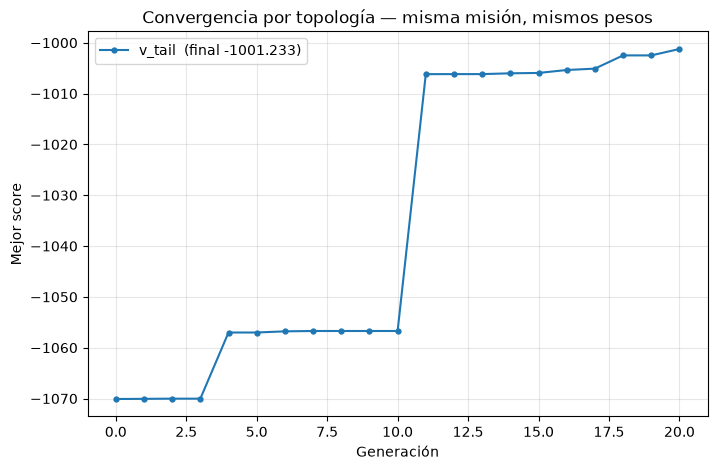

In [13]:
plt.figure(figsize=(8, 5))
for t, est in sorted(estados.items(), key=lambda kv: -kv[1].mejor().score):
    gens = [h["generation"] for h in est.historial]
    mejores = [max(h["parent_scores"]) for h in est.historial]
    plt.plot(gens, mejores, marker="o", markersize=3.5, label=f"{t}  (final {est.mejor().score:.3f})")

plt.xlabel("Generación")
plt.ylabel("Mejor score")
plt.title("Convergencia por topología — misma misión, mismos pesos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Tabla comparativa de los ganadores

Una fila por topología, con las magnitudes que de verdad separan a los candidatos. Vale la pena mirar sobre todo tres cosas: la **superficie de ala** que eligió cada una (que es el compromiso central de esta misión), el **margen de vuelo lento**, y el **volumen de cola** $V_H$ — si alguna cayó muy fuera del rango de referencia (0.5–0.7), conviene revisar los bounds de esa topología antes de creerle el resultado.

In [14]:
filas = []
for t, est in estados.items():
    a = av.analizar_mision_avion(est.mejor().params, t)
    if a is None:
        continue
    filas.append({
        "topologia": t, "score": est.mejor().score,
        "b_m": a["envergadura"], "S_m2": a["S"], "AR": a["AR"],
        "masa_kg": a["masa_total"], "%estr": 100*a["fraccion_estructural"],
        "E_Wh": av.energia_mision_wh(a),
        "L/D_cru": a["LD_crucero"], "D_N": a["D_crucero"], "P_W": a["potencia_W"],
        "v_stall": a["v_stall"], "margen_lento_%": 100*a["margen_lento"],
        "SM_%": 100*a["SM"], "Cm_cru": a["Cm_crucero"], "inc_trim": a["incidencia_trim_deg"],
        "V_H": a["V_H"], "V_V": a["V_V"],
        "Cn_r": a["Cn_r"],
    })
df = pd.DataFrame(filas).sort_values("score", ascending=False).round(3)
display(df)
print("Referencia de volumen de cola para esta clase: V_H 0.5-0.7, V_V 0.02-0.05")
print("(Scholz, INCAS Bulletin 13(3), 2021). No son restricciones: se reportan")
print("para poder decir si el resultado cayo en territorio conocido.")

,topologia,score,b_m,S_m2,AR,masa_kg,%estr,E_Wh,L/D_cru,D_N,P_W,v_stall,margen_lento_%,SM_%,Cm_cru,inc_trim,V_H,V_V,Cn_r
0,v_tail,-1001.233,2.94,1.111,7.782,11.614,29.444,1149.145,19.087,5.983,132.958,9.995,0.275,9.296,0.0,-0.678,0.23,0.026,-0.088


Referencia de volumen de cola para esta clase: V_H 0.5-0.7, V_V 0.02-0.05
(Scholz, INCAS Bulletin 13(3), 2021). No son restricciones: se reportan
para poder decir si el resultado cayo en territorio conocido.


In [15]:
# Bateria de cada ganador (solo si BATERIA = True en la seccion 0)
filas_b = []
for t, est in estados.items():
    a = av.analizar_mision_avion(est.mejor().params, t)
    if a is None or not a.get("bateria"):
        continue
    b = a["bateria"]; pk = b["pack"]; d = b["despegue"]
    filas_b.append({
        "topologia": t, "masa_total_kg": a["masa_total"], "bateria_kg": a["masa_bateria"],
        "bateria_%": 100*b["fraccion_masa_bateria"], "pack": f"{pk['S']}S{pk['P']}P",
        "capacidad_Ah": pk["capacidad_Ah"], "energia_Wh": b["energia_requerida_wh"],
        "volumen_L": b["volumen_bateria_l"], "alcance_km": b["alcance_logrado_km"],
        "P_cruc_W": b["potencia_electrica_crucero_W"], "I_cruc_A": b["corriente_crucero_A"],
        "empuje_despegue_kgf": d["empuje_kgf"], "I_despegue_A": d["corriente_A"],
        "I_max_pack_A": pk["corriente_continua_max_A"],
    })
if filas_b:
    display(pd.DataFrame(filas_b).sort_values("bateria_kg").round(2))
    print("Alcance a velocidad de crucero TODO el vuelo; la reserva cubre despegue, ascenso y aterrizaje.")
    print("Despegue: disco actuador con T/W = 0.45, helice de 15 pulgadas (informativo, no puntua).")
else:
    print("BATERIA = False: no hay modelo de bateria en este escenario.")

,topologia,masa_total_kg,bateria_kg,bateria_%,pack,capacidad_Ah,energia_Wh,volumen_L,alcance_km,P_cruc_W,I_cruc_A,empuje_despegue_kgf,I_despegue_A,I_max_pack_A
0,v_tail,11.61,4.19,36.11,12S5P,32.5,1149.14,1.91,348.89,218.88,5.07,5.23,33.39,130.0


Alcance a velocidad de crucero TODO el vuelo; la reserva cubre despegue, ascenso y aterrizaje.
Despegue: disco actuador con T/W = 0.45, helice de 15 pulgadas (informativo, no puntua).


## 7. Análisis de misión completo de cada ganador

Desglose término por término: masa calculada pieza por pieza, los dos puntos de vuelo, las tres reglas de oro de estabilidad estática, las derivadas de amortiguamiento y el aporte de cada término al score.

Sobre las **derivadas de amortiguamiento** ($C_{l_p}$, $C_{n_r}$, $C_{n_p}$, $C_{l_r}$): se calculan y se reportan, pero **no se puntúan ni se restringen**. La razón es honesta — no tenemos una banda de referencia bibliográfica para ellas en esta clase de avión, y poner un umbral inventado sería peor que no ponerlo. Lo esperable es $C_{l_p} < 0$ y $C_{n_r} < 0$ (los dos amortiguan); un $C_{n_r}$ chico en valor absoluto es la señal de alarma para Dutch roll.

In [16]:
for t, est in sorted(estados.items(), key=lambda kv: -kv[1].mejor().score):
    print(av.desglose_mision_avion(est.mejor().params, t))
    print("\n" + "="*78 + "\n")

=== [v_tail] MISION: crucero (diseno) 80 km/h + vuelo lento 10 m/s + maxima 120 km/h, con 3.0 kg de carga util ===

VOLUMEN DE FUSELAJE  geometrico  19.42 L  x 55% util. =  10.68 L util  (requerido >= 9.6 L)

MASA (calculada, no declarada)
  carga util ............   3.00 kg
  sistemas ..............   1.00 kg   (sin bateria)
  bateria ...............   4.19 kg   (36% de la masa total)
  estructura ............   3.42 kg
     larguero 0.027 | piel ala 2.276 | winglet 0.000 | flap 0.141
     cola 0.364 | fuselaje 0.612 | boom 0.000
  TOTAL .................  11.61 kg   (29% estructura)
  flecha en punta .......   73.5 mm  (la rigidez dimensiona el larguero)

GEOMETRIA
  envergadura ...........   2.94 m ala, 2.93 m total con winglets   (maximo 3.0 m, SORA)
  superficie ............  1.111 m2   AR = 7.8   MAC = 0.402 m
  carga alar ............  102.6 N/m2
  volumen de cola ....... V_H = 0.230   V_V = 0.0257   (ref. clase: V_H 0.5-0.7, V_V 0.02-0.05)

CRUCERO a 80 km/h   (Re = 526,312)
  

## 8. Vista 3D del ganador

In [17]:
top_ganadora, est_ganador = max(estados.items(), key=lambda kv: kv[1].mejor().score)
mejor = est_ganador.mejor()

print(f"Ganador: {top_ganadora}  (score {mejor.score:.4f})")
print(f"  {av.TOPOLOGIAS[top_ganadora]['nombre']}")
print(f"  referencia real: {av.TOPOLOGIAS[top_ganadora]['referencia_real']}")

# Vista propia: un color por componente (ala, cola, fuselaje), escala 1:1 y los datos
# del avion. (avion.draw(backend="plotly") de AeroSandbox pone una barra de colores
# que no representa nada.)
_a = av.analizar_mision_avion(mejor.params, top_ganadora)
avion = av.construir_avion(av.params_trimados(mejor.params, top_ganadora), top_ganadora)   # con la incidencia de trim
av.figura_3d(avion, f"{top_ganadora} (ganador)", av.lineas_info(_a, mejor.score)).show()

Ganador: v_tail  (score -1001.2333)
  Ala + fuselaje + cola en V
  referencia real: Familia MQ-1 Predator (cola en V invertida)


## 8b. Líneas de flujo del ganador (VLM)

El avión **trimado** en el punto de **crucero** de la misión (su alpha, 80 km/h, la densidad del escenario), resuelto con el método de red de vórtices (VLM) de AeroSandbox. Los paneles se pintan con la **circulación Γ** de cada vórtice [m²/s]: dónde el ala genera más sustentación. Las líneas violetas son líneas de flujo: se ven la estela y el torbellino de punta.

**Es solo para visualizar.** El VLM es potencial e inviscido: no ve el fuselaje (se dibuja en gris como referencia), no capta toda la sustentación de los perfiles con mucha curvatura, y el CD que da es solo el inducido. Los números del optimizador salen de AeroBuildup (el recuadro muestra los dos). Tarda ~20 s. Para ver otra familia, cambiá `FAMILIA_FLUJO`.

In [18]:
FAMILIA_FLUJO = top_ganadora          # o cualquiera de TOPOLOGIAS_A_CORRER, p. ej. "pod_boom"

fig_flujo, datos_flujo = av.figura_flujo(estados[FAMILIA_FLUJO].mejor().params, FAMILIA_FLUJO)
if fig_flujo is None:
    print(f"[{FAMILIA_FLUJO}] el mejor avion es infactible: {datos_flujo['motivo']}")
else:
    fig_flujo.show()

## 9. El modelo de flap, y el compromiso que descubre

Lo habitual en diseño preliminar es sumar un $\Delta CL_{max}$ de tabla según el tipo de flap (Raymer/Roskam: plain ~0.9, ranurado ~1.3, Fowler ~1.9). Esas tablas están medidas a Reynolds de avión grande ($10^6$–$10^7$) y este avión vuela lento a Re ≈ $2\times10^5$. La bibliografía ([ICAS 2010, paper 246](https://icas.org/icas_archive/ICAS2010/PAPERS/246.PDF)) dice que a Re bajo la curva con flap se vuelve no lineal y el $CL_{max}$ cae, pero **no publica un factor de corrección**.

En vez de inventarlo, acá el incremento se **mide**: se deflecta la geometría del perfil y se la evalúa con NeuralFoil al Reynolds real del vuelo lento — el mismo modelo que se usa en todo el resto del pipeline.

La celda de abajo muestra el resultado, que tiene una consecuencia de diseño que no es obvia: **el perfil de alta sustentación y el flap compiten, no se suman.** Sobre un perfil ya muy cambado, deflectar mucho un flap grande lo separa antes en vez de darle más sustentación — el e423 a 40° da *menos* CL_max que limpio. Es física real del modelo, no un artefacto, y es uno de los compromisos que el optimizador tiene que resolver.

> **Limitación honesta:** deflectar el contorno modela bien un flap **plain** (sin ranura). Un flap ranurado o Fowler tiene física que esto no captura (la ranura reenergiza la capa límite; el Fowler además agranda la superficie), así que ofrecerlos sería prometer un $CL_{max}$ que el modelo no puede sostener. El flap plain es además el realista para construcción artesanal.

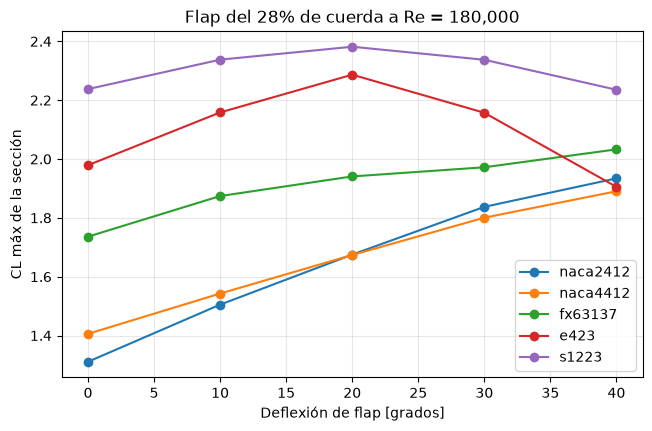

,perfil,0deg,10deg,20deg,30deg,40deg
0,naca2412,1.311,1.505,1.675,1.837,1.934
1,naca4412,1.406,1.543,1.674,1.801,1.890
2,fx63137,1.736,1.874,1.941,1.972,2.033
3,e423,1.979,2.158,2.287,2.157,1.905
4,s1223,2.238,2.338,2.382,2.337,2.235


Los perfiles muy cambados (e423, s1223) PIERDEN CL_max si se los deflecta
mucho: ya estan al borde de la separacion. El optimo de deflexion baja
a medida que sube el camber del perfil base.


In [19]:
from optimizacion_avion.perfiles_avion import cargar_perfil_avion, perfil_con_flap

alphas = np.linspace(0, 24, 49)
Re_lento = 1.8e5
deflexiones = [0, 10, 20, 30, 40]
perfiles = ["naca2412", "naca4412", "fx63137", "e423", "s1223"]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
tabla = []
for n in perfiles:
    af = cargar_perfil_avion(n)
    fila = {"perfil": n}
    ys = []
    for d in deflexiones:
        a2 = perfil_con_flap(af, d, 0.28)
        cl = float(np.max(a2.get_aero_from_neuralfoil(alpha=alphas, Re=Re_lento, mach=0.03)["CL"]))
        fila[f"{d}deg"] = round(cl, 3)
        ys.append(cl)
    tabla.append(fila)
    ax.plot(deflexiones, ys, marker="o", label=n)

ax.set_xlabel("Deflexión de flap [grados]")
ax.set_ylabel("CL máx de la sección")
ax.set_title(f"Flap del 28% de cuerda a Re = {Re_lento:,.0f}")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

display(pd.DataFrame(tabla))
print("Los perfiles muy cambados (e423, s1223) PIERDEN CL_max si se los deflecta")
print("mucho: ya estan al borde de la separacion. El optimo de deflexion baja")
print("a medida que sube el camber del perfil base.")

## 10. El catálogo de perfiles a los dos Reynolds

Los índices 0 a 11 son **los mismos** que en el ala volante (no se pueden reordenar sin cambiarle el significado a todos los diseños ya guardados de aquel notebook); del 12 al 18 son los de alta sustentación agregados para esta misión.

El orden sigue siendo por $C_{m0}$ y eso no es cosmético: el GA cruza índices con BLX-alfa, o sea que **interpola**, y para que interpolar tenga sentido los índices vecinos tienen que ser diseños vecinos. En el tramo nuevo ese orden coincide además con $CL_{max}$ creciente, que es lo que uno quiere que recorra una mutación cuando el binding constraint es el vuelo lento.

**Lo que la tabla no dice:** el $L/D$ máximo de los perfiles nuevos es altísimo, pero ocurre a CL alto. En crucero a 120 km/h el CL del ala es ~0.1–0.3, y ahí un perfil muy cambado es un mal negocio. No hay que leer la tabla como "los de abajo son mejores": son mejores **para volar lento** y peores para crucero.

In [20]:
print(av.resumen_catalogo_avion(re_lento=2.0e5, re_crucero=6.7e5))

idx  perfil     Cm0       espesor  CLmax@670k  CLmax@200k
  0  naca2412   -0.0547    12.0%      1.415       1.313
  1  rg15       -0.0647     8.9%      1.285       1.173
  2  mh60       -0.0006    10.1%      1.300       1.202
  3  s5010      +0.0072     9.8%      1.376       1.240
  4  eh3012     -0.0007    12.0%      1.233       1.225
  5  eh2010     +0.0066    10.1%      1.169       1.135
  6  eh2012     +0.0061    12.0%      1.222       1.133
  7  clarkys    +0.0301    11.7%      1.315       1.218
  8  e186       +0.0258    10.3%      1.074       1.026
  9  mh80       +0.0154    12.7%      1.601       1.513
 10  e340       +0.0489    13.7%      1.334       1.358
 11  mh78       +0.0499    14.5%      1.518       1.348
 12  naca4412   -0.1040    12.0%      1.531       1.400  <- alta sustentacion
 13  naca6412   -0.1521    12.0%      1.639       1.612  <- alta sustentacion
 14  sd7062     -0.0857    14.0%      1.659       1.563  <- alta sustentacion
 15  fx63137    -0.2135    13.7%    

## 11. Exportar el diseño ganador

In [21]:
a = av.analizar_mision_avion(mejor.params, top_ganadora)
p = a["params_trimados"]      # el avion que se analizo: incidencia de cola resuelta para Cm = 0

salida = {
    "topologia": top_ganadora,
    "descripcion": av.TOPOLOGIAS[top_ganadora]["nombre"],
    "referencia_real": av.TOPOLOGIAS[top_ganadora]["referencia_real"],
    "generation": est_ganador.generation,
    "score": mejor.score,
    "_mision": {
        "velocidad_crucero_kmh": 3.6 * mis.V_CRUCERO,
        "velocidad_lenta_ms": mis.V_LENTO,
        "margen_sobre_perdida": mis.MARGEN_SOBRE_PERDIDA,
        "carga_util_kg": mis.MASA_PAYLOAD,
        "rafaga_vertical_ms": mis._rafaga_vertical(),   # 4.63 con viento, 3.0 sin
        "densidad_kg_m3": float(a["rho"]),
        "viento_activo": bool(mis.VIENTO_ACTIVO),
        "bateria_activa": bool(mis.BATERIA_ACTIVA),
        "banda_margen_estatico": list(av.SM_BANDS[top_ganadora]),
    },
    "parametros": {k: round(float(v), 5) for k, v in sorted(p.items())},
    "perfiles": {
        "raiz": av.indice_a_nombre_avion(p["perfil_raiz"]),
        "medio": av.indice_a_nombre_avion(p["perfil_medio"]),
        "punta": av.indice_a_nombre_avion(p["perfil_punta"]),
        "posicion_del_medio_frac_semienvergadura": p["perfil_pos_medio"],
        "_nota": "perfiles REALES de la base UIUC; las secciones intermedias son mezclas lineales",
    },
    "resultados": {k: (float(a[k]) if isinstance(a[k], (int, float, np.floating)) else a[k])
                   for k in ("masa_total", "fraccion_estructural", "envergadura", "S", "AR",
                             "LD_crucero", "D_crucero", "potencia_W", "alpha_crucero",
                             "v_stall", "margen_lento", "CL_max_lento", "CL_lento",
                             "SM", "Cm_alpha_por_grado", "Cm_crucero",
                             "Cn_beta", "Cl_beta", "Cl_p", "Cn_r", "Cn_p", "Cl_r",
                             "V_H", "V_V", "margen_perdida")},
}

if a.get("bateria"):
    salida["bateria"] = json.loads(json.dumps(a["bateria"], default=float))
    salida["_mision"]["alcance_km"] = a["bateria"]["alcance_objetivo_km"]

ruta = Path(f"avion_design_params_{top_ganadora}.json")
ruta.write_text(json.dumps(salida, indent=2, default=float), encoding="utf-8")
print(f"Guardado en {ruta.resolve()}")
print(json.dumps(salida, indent=2, default=float)[:2500])

Guardado en C:\Users\Usuario\Documents\Proyecto final\genetic_wing\avion_design_params_v_tail.json
{
  "topologia": "v_tail",
  "descripcion": "Ala + fuselaje + cola en V",
  "referencia_real": "Familia MQ-1 Predator (cola en V invertida)",
  "generation": 20,
  "score": -1001.2333273164688,
  "_mision": {
    "velocidad_crucero_kmh": 80.0,
    "velocidad_lenta_ms": 10.0,
    "margen_sobre_perdida": 1.2,
    "carga_util_kg": 3.0,
    "rafaga_vertical_ms": 4.63,
    "densidad_kg_m3": 1.0560000000000025,
    "viento_activo": true,
    "bateria_activa": true,
    "banda_margen_estatico": [
      0.1,
      0.2
    ],
    "alcance_km": 350.0
  },
  "parametros": {
    "ala_x_frac_fuselaje": 0.26261,
    "boattail_largo_frac": 0.37188,
    "boattail_radio_frac": 0.14303,
    "cg_frac_mac": 0.34211,
    "chord_1": 0.47504,
    "chord_2": 0.41996,
    "chord_3": 0.25254,
    "chord_4": 0.25254,
    "elev_1": 0.01941,
    "elev_2": 0.01941,
    "elev_3": 0.04583,
    "elev_4": 0.06348,
    "en

## 11b. Guardar los resultados de esta corrida

Crea `<CARPETA_RESULTADOS>/<fecha>_<hora>_<escenario>_<familias>/` **fuera del repositorio** (por defecto `Proyecto final/resultados_optimizador/`) con: `LEEME.md` (qué se corrió y la tabla final), `tabla_resumen.csv`, `ganadores.json` (params **trimados**, listos para `exportar_cad_avion.py`), `convergencia.png`, `comparacion.png`, `curvas_vuelo.png`, `vistas_3d/<familia>.html`, `lineas_flujo/<familia>.html`, `tres_vistas/<familia>.png` y `desgloses/<familia>.txt`. Nunca pisa una carpeta anterior. La nomenclatura está en el `LEEME.md` de esa carpeta.

In [22]:
if GUARDAR_RESULTADOS:
    carpeta = av.guardar_resultados(
        estados, carpeta_base=CARPETA_RESULTADOS,
        etiqueta=None,            # p. ej. etiqueta="prueba_eta070"
        flujo=True,               # False saltea las lineas de flujo (~20 s y ~3 MB por familia)
        parametros_ga={"paciencia": PACIENCIA, "max_generaciones": MAX_GENERACIONES,
                       "hijos_por_generacion": N_CROSSBRED + N_WILDCARD, "semilla_azar": SEMILLA_AZAR,
                       "semillas": SET_SEMILLAS or "las del escenario"})
else:
    print("GUARDAR_RESULTADOS = False (seccion 0): no se guardo nada.")

Resultados guardados en C:\Users\Usuario\Documents\Proyecto final\resultados_optimizador\2026-10-19_2053_viento-on_bateria-on_v_tail


## 12. Lo que este modelo TODAVÍA no hace

Conviene tenerlo escrito para no confundir *"no está implementado"* con *"salió que no importa"*:

- **Exportación a CAD, con un límite.** `exportar_cad_avion.py` y `fusion_generar_avion.py` llevan el avión completo (ala, fuselaje, cola) a Fusion: el primero escribe las secciones 3D en `avion_geometry_cad.json` y el segundo las dibuja dentro de Fusion (ver también `exportar_cfd_avion.py`, que escribe el caso de cálculo y compara el drag con un CFD). Lo que **no** hay: el script de Fusion se escribió sin poder ejecutarlo en Fusion, así que la parte de la API (revolución del fuselaje, espejado, unión de cuerpos) está sin probar hasta que se corra; no hay hélice ni spinner; y `exportar_cad.py` / `fusion_generar_ala.py` siguen siendo solo para el ala volante.
- **El flap es solo plain.** Sin flap ranurado ni Fowler (ver sección 9).
- **La masa de las vigas es declarada**, no dimensionada por flexión. Aplica al `doble_boom` (el `pod_boom` ya no tiene viga: es un fuselaje continuo). `boom_diametro` ya existe como variable geométrica y afecta la resistencia, pero no se usa para dimensionar: sería el próximo paso natural.
- **Torsión y flutter del ala no se ven.** Con la envergadura ahora **libre** esto importa más que antes: el criterio de rigidez en flexión frena el alargamiento, pero un ala muy esbelta puede ser inviable por torsión mucho antes.
- **Las superficies de cola no tienen larguero dimensionado**, solo masa de recubrimiento.
- **Las derivadas de amortiguamiento no se convierten en modos dinámicos** (frecuencia y amortiguamiento de Dutch roll). Para eso harían falta los momentos de inercia: el modelo de masa sabe *cuánto* pesa cada pieza, no *cómo está distribuida*.
- **No hay superficies de control más allá del flap.** Ni elevador, ni ruddervators, ni alerones: se evalúa la estabilidad de la configuración, no su controlabilidad ni la resistencia de trim con elevador deflectado.
- **Batería (rama `bateria-350km`).** Con `BATERIA = True` hay un modelo de energía: la masa de batería sale del alcance pedido a velocidad de crucero constante. Lo que **no** modela: ascenso y descenso aparte, viento de frente, degradación de la celda ni la curva de descarga (la reserva del 20 % cubre todo eso de forma gruesa). El rendimiento propulsivo (0.65) es un supuesto, no un dato de hélice y motor. Con `BATERIA = False` vuelve el problema de antes: `MASA_SISTEMAS` es una constante de 1.5 kg que incluye la batería y el modelo no ve que la autonomía cae.